# Equipment anomaly detection: catching a device before it fails

**Question:** can we notice that a ventilator, monitor or infusion pump is going wrong **before it fails**?

**Two approaches:**

| Approach | How it decides "something's wrong" |
|---|---|
| **Fixed limits** (MedTwin's current alert rules) | temperature crosses a set line: 44 °C ventilator, 40 °C monitor, 37 °C pump |
| **Isolation Forest** | learns what *normal* readings look like, and flags anything unusual in **any combination** of signals. It needs **no examples of failures**. |

**Ground truth:** the simulator recorded every fault it injected (start, failure time), so we know exactly when each
device was really going wrong.

**Fair comparison:** time split: training (older months), **validation** (the month before last, to set the
Isolation Forest's alarm level), **test** (last month). Both approaches need **2 unusual readings in a row**
(20 minutes) before alarming.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, roc_auc_score

DATA, MODELS, RESULTS = Path("../data"), Path("../models"), Path("../results")
telemetry = pd.read_csv(DATA / "telemetry.csv.gz", parse_dates=["recorded_at"])
faults = pd.read_csv(DATA / "faults.csv", parse_dates=["started_at", "failed_at", "cleared_at"])
print(f"{len(telemetry):,} readings from {telemetry.equipment.nunique()} devices · {len(faults)} injected faults "
      f"({faults.failed_at.notna().sum()} ended in failure)")
telemetry.groupby("kind").agg(devices=("equipment", "nunique"), readings=("equipment", "size"),
                              median_temperature=("temperature", "median")).round(1)

752,410 readings from 30 devices · 87 injected faults (87 ended in failure)


,devices,readings,median_temperature
kind,,,
INFUSION_PUMP,6,151206,32.9
MONITOR,16,399577,35.8
VENTILATOR,8,201627,39.9


## Labelling the readings

A reading is **faulty** if it falls between a fault's start and the device's failure (or its repair, if it was
caught first).

In [2]:
telemetry = telemetry.sort_values(["equipment", "recorded_at"]).reset_index(drop=True)
telemetry["faulty"] = False
for fault in faults.itertuples():
    end = fault.failed_at if pd.notna(fault.failed_at) else fault.cleared_at
    if pd.isna(end):
        end = telemetry.recorded_at.max()
    inside = (telemetry.equipment == fault.equipment) & telemetry.recorded_at.between(fault.started_at, end)
    telemetry.loc[inside, "faulty"] = True
print(f"{100 * telemetry.faulty.mean():.2f}% of readings are during a developing fault")

1.58% of readings are during a developing fault


## Features: what the Isolation Forest looks at

In [3]:
WINDOW = 12  # 12 readings = 2 hours (one reading every 10 minutes)
by_device = telemetry.groupby("equipment", sort=False)
smoothed = by_device["temperature"].transform(lambda t: t.rolling(3, min_periods=1).mean())
normal = by_device["temperature"].transform(lambda t: t.rolling(432, min_periods=12).median().shift(1))  # 3 days

telemetry["temperature_above_normal"] = telemetry["temperature"] - normal
telemetry["temperature_trend_2h"] = smoothed - smoothed.groupby(telemetry.equipment).shift(WINDOW)
telemetry["errors_2h"] = by_device["error_count"].transform(lambda e: e.rolling(WINDOW, min_periods=1).sum())
telemetry["pressure_spread_2h"] = by_device["pressure"].transform(lambda p: p.rolling(WINDOW, min_periods=3).std()).fillna(0)

FEATURES = ["temperature", "temperature_above_normal", "temperature_trend_2h", "errors_2h", "pressure_spread_2h"]
telemetry = telemetry.dropna(subset=FEATURES)

end = telemetry.recorded_at.max()
test_start, validation_start = end - pd.Timedelta(days=30), end - pd.Timedelta(days=60)
telemetry["period"] = np.select([telemetry.recorded_at >= test_start, telemetry.recorded_at >= validation_start],
                                ["test", "validation"], "train")
telemetry.groupby("period").agg(readings=("faulty", "size"), faulty_readings=("faulty", "sum"))

,readings,faulty_readings
period,,
test,125337,2205
train,502385,7295
validation,124328,2417


In [4]:
def two_in_a_row(flag):
    """An alarm needs 2 unusual readings in a row on the same device."""
    previous = flag.groupby(telemetry.equipment).shift(1, fill_value=False)
    return flag & previous


def event_results(method, period):
    data = telemetry[telemetry.period == period]
    period_faults = faults[faults.started_at.between(data.recorded_at.min(), data.recorded_at.max())]
    caught, warning_hours, delay_hours = 0, [], []
    for fault in period_faults.itertuples():
        end = fault.failed_at if pd.notna(fault.failed_at) else fault.cleared_at
        window = data[(data.equipment == fault.equipment) & data.recorded_at.between(fault.started_at, end)]
        alarms = window.loc[window[method], "recorded_at"]
        if len(alarms) and pd.notna(fault.failed_at):
            caught += 1
            warning_hours.append((fault.failed_at - alarms.iloc[0]) / pd.Timedelta(hours=1))
            delay_hours.append((alarms.iloc[0] - fault.started_at) / pd.Timedelta(hours=1))
    healthy = data[~data.faulty]
    episodes = (healthy[method] & ~healthy.groupby("equipment")[method].shift(1, fill_value=False)).sum()
    device_weeks = healthy.equipment.nunique() * (healthy.recorded_at.max() - healthy.recorded_at.min()) / pd.Timedelta(weeks=1)
    return {
        "faults": len(period_faults),
        "caught before failure %": 100 * caught / max(1, period_faults.failed_at.notna().sum()),
        "median hours of warning": np.median(warning_hours) if warning_hours else np.nan,
        "median hours from fault start to alarm": np.median(delay_hours) if delay_hours else np.nan,
        "false alarms per device-week": episodes / device_weeks,
        "reading recall %": 100 * data.loc[data.faulty, method].mean(),
        "reading precision %": 100 * data.loc[data[method], "faulty"].mean() if data[method].any() else np.nan,
    }

## Training, and setting the alarm level

One Isolation Forest per kind of device, trained on the **training months only**, without any labels.

**Choosing its alarm level fairly:** the false-alarm budget is decided **in advance**: at most **0.5 false alarms per
device per week** (about one every two weeks). On the **validation month**, several alarm levels are tried, and the
one that catches the most faults, with the most warning, within that budget is kept. Only then is the test month used.

In [5]:
LIMITS = {"VENTILATOR": 44, "MONITOR": 40, "INFUSION_PUMP": 37}  # MedTwin's current alert rules
FALSE_ALARM_BUDGET = 0.5  # at most this many false alarms per device per week, decided in advance

forests, levels = {}, {}
telemetry["anomaly_score"] = np.nan
for kind, part in telemetry.groupby("kind"):
    forest = IsolationForest(n_estimators=200, max_samples=4096, random_state=0, n_jobs=-1)
    forest.fit(part.loc[part.period == "train", FEATURES])
    score = -forest.score_samples(part[FEATURES])  # higher = more unusual
    telemetry.loc[part.index, "anomaly_score"] = score
    forests[kind] = forest


def levels_for(rate):
    # Per kind: the score that flags `rate` of the healthy validation readings.
    healthy = telemetry[(telemetry.period == "validation") & ~telemetry.faulty]
    return {kind: float(np.quantile(part.anomaly_score, 1 - rate)) for kind, part in healthy.groupby("kind")}


candidates = []
for rate in (0.001, 0.0025, 0.005, 0.01, 0.02):
    telemetry["alarm_candidate"] = two_in_a_row(telemetry.anomaly_score >= telemetry.kind.map(levels_for(rate)))
    candidates.append({"false-alarm readings allowed": rate, **event_results("alarm_candidate", "validation")})
choice = pd.DataFrame(candidates)
within_budget = choice[choice["false alarms per device-week"] <= FALSE_ALARM_BUDGET]
FALSE_ALARM_RATE = float(within_budget.sort_values(["caught before failure %", "median hours of warning"],
                                                   ascending=False).iloc[0]["false-alarm readings allowed"])
levels = levels_for(FALSE_ALARM_RATE)

telemetry["alarm_fixed"] = two_in_a_row(telemetry.temperature >= telemetry.kind.map(LIMITS))
telemetry["alarm_forest"] = two_in_a_row(telemetry.anomaly_score >= telemetry.kind.map(levels))
print(f"Chosen on the validation month: {FALSE_ALARM_RATE:.2%} false-alarm readings allowed")
choice.set_index("false-alarm readings allowed")[["caught before failure %", "median hours of warning",
                                                  "false alarms per device-week"]].round(2)

Chosen on the validation month: 0.50% false-alarm readings allowed


,caught before failure %,median hours of warning,false alarms per device-week
false-alarm readings allowed,,,
0.0010,77.78,4.17,0.12
0.0025,100.00,14.25,0.18
0.0050,100.00,18.50,0.40
0.0100,100.00,19.25,0.94
0.0200,100.00,19.42,2.68


## Results on the test month

* **Faults caught before failure:** did the method alarm at any point between the fault starting and the device failing?
* **Hours of warning:** from the first alarm to the failure (more time = time to swap the device safely).
* **False alarms per device per week:** separate alarm episodes on healthy devices.

In [6]:
rows = [{"method": name, **event_results(column, "test")}
        for name, column in [("Fixed limits", "alarm_fixed"), ("Isolation Forest", "alarm_forest")]]
results = pd.DataFrame(rows).set_index("method")
test = telemetry[telemetry.period == "test"]
results["AUROC (readings)"] = [roc_auc_score(test.faulty, test.temperature - test.kind.map(LIMITS)),
                               roc_auc_score(test.faulty, test.anomaly_score)]
results.to_csv(RESULTS / "equipment_anomaly_results.csv")
results.round(2).T

method,Fixed limits,Isolation Forest
faults,16.00,16.00
caught before failure %,100.00,100.00
median hours of warning,10.75,16.42
median hours from fault start to alarm,9.42,4.00
false alarms per device-week,0.00,0.46
reading recall %,47.12,77.23
reading precision %,100.00,85.53
AUROC (readings),0.94,0.96


## The trade-off: a stricter or looser Isolation Forest

For transparency, the same alarm levels **on the test month** (the choice above was made on validation only).
It shows the balance between catching faults early and raising false alarms.

In [7]:
sweep = []
for rate in (0.001, 0.005, 0.01, 0.02):
    flags = pd.Series(False, index=telemetry.index)
    for kind, part in telemetry.groupby("kind"):
        healthy_validation = (part.period == "validation") & ~part.faulty
        level = np.quantile(part.loc[healthy_validation, "anomaly_score"], 1 - rate)
        flags[part.index] = part.anomaly_score >= level
    telemetry["alarm_sweep"] = two_in_a_row(flags)
    sweep.append({"false-alarm readings allowed": f"{rate:.1%}", **event_results("alarm_sweep", "test")})
fixed_row = {"false-alarm readings allowed": "Fixed limits", **event_results("alarm_fixed", "test")}
tradeoff = pd.DataFrame([fixed_row, *sweep]).set_index("false-alarm readings allowed")
tradeoff.to_csv(RESULTS / "equipment_anomaly_tradeoff.csv")
tradeoff[["caught before failure %", "median hours of warning", "false alarms per device-week"]].round(2)

,caught before failure %,median hours of warning,false alarms per device-week
false-alarm readings allowed,,,
Fixed limits,100.00,10.75,0.00
0.1%,81.25,6.00,0.12
0.5%,100.00,16.42,0.46
1.0%,100.00,17.08,1.11
2.0%,100.00,17.83,2.55


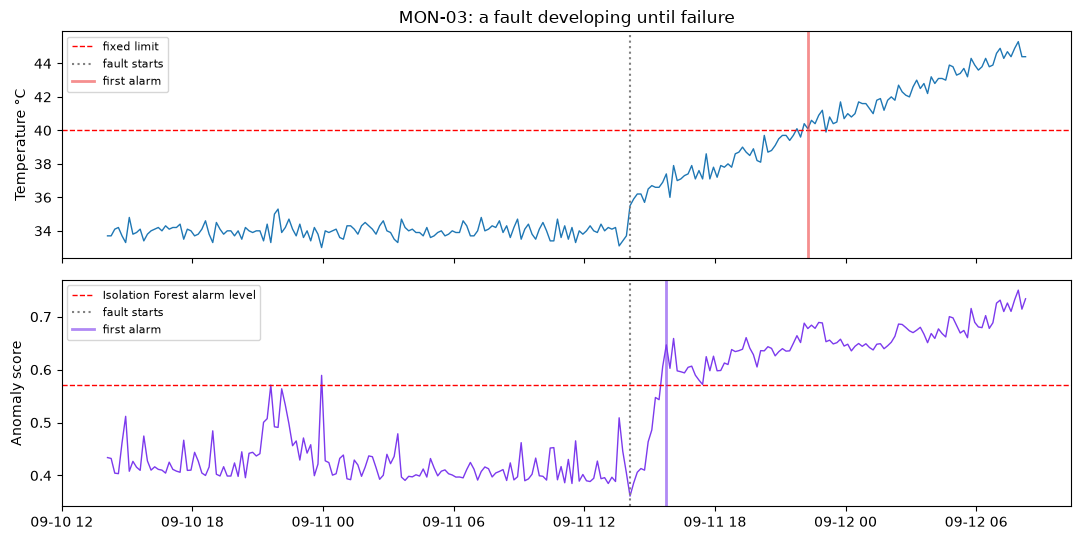

In [8]:
caught = faults[faults.started_at >= test_start].dropna(subset=["failed_at"]).iloc[0]
device = telemetry[(telemetry.equipment == caught.equipment)
                   & telemetry.recorded_at.between(caught.started_at - pd.Timedelta(hours=24), caught.failed_at)]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
top.plot(device.recorded_at, device.temperature, lw=1)
top.axhline(LIMITS[caught.kind], color="red", ls="--", lw=1, label="fixed limit")
top.set_ylabel("Temperature °C")
top.set_title(f"{caught.code}: a fault developing until failure")
bottom.plot(device.recorded_at, device.anomaly_score, lw=1, color="#7c3aed")
bottom.axhline(levels[caught.kind], color="red", ls="--", lw=1, label="Isolation Forest alarm level")
bottom.set_ylabel("Anomaly score")
for ax in (top, bottom):
    ax.axvline(caught.started_at, color="grey", ls=":", label="fault starts")
    for column, color in (("alarm_fixed", "#ef4444"), ("alarm_forest", "#7c3aed")):
        first = device.loc[device[column], "recorded_at"]
        if len(first) and ax is (top if column == "alarm_fixed" else bottom):
            ax.axvline(first.iloc[0], color=color, lw=2, alpha=0.6, label="first alarm")
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "equipment_anomaly_example.png", dpi=150)
plt.show()

## A public benchmark: AI4I 2020

**AI4I 2020** (Matzka, 2020; UCI Machine Learning Repository) is a public predictive-maintenance dataset: 10,000
machine records with temperatures, speed, torque and tool wear, and whether the machine failed. Can an Isolation
Forest, which never sees a failure label, rank failing records above healthy ones better than watching any single
signal on its own (like a fixed limit does)?

In [9]:
ai4i = pd.read_csv(DATA / "ai4i" / "ai4i2020.csv")
signals = {
    "Air temperature": ai4i["Air temperature [K]"], "Process temperature": ai4i["Process temperature [K]"],
    "Rotational speed": ai4i["Rotational speed [rpm]"], "Torque": ai4i["Torque [Nm]"], "Tool wear": ai4i["Tool wear [min]"],
}
X = pd.DataFrame(signals)
X["Temperature difference"] = X["Process temperature"] - X["Air temperature"]
X["Power"] = X["Torque"] * X["Rotational speed"] * 2 * np.pi / 60
failed = ai4i["Machine failure"]

forest = IsolationForest(n_estimators=300, random_state=0).fit(X)
rows = [{"approach": "Isolation Forest (all signals, no labels)",
         "AUROC": roc_auc_score(failed, -forest.score_samples(X)),
         "AUPRC": average_precision_score(failed, -forest.score_samples(X))}]
for name, values in X.items():
    # a single signal used as a limit, in whichever direction is more telling
    auroc = roc_auc_score(failed, values)
    direction = values if auroc >= 0.5 else -values
    rows.append({"approach": f"Single signal: {name}", "AUROC": max(auroc, 1 - auroc),
                 "AUPRC": average_precision_score(failed, direction)})
benchmark = pd.DataFrame(rows).set_index("approach").sort_values("AUROC", ascending=False)
benchmark.to_csv(RESULTS / "equipment_anomaly_ai4i.csv")
print(f"{len(ai4i):,} records, {100 * failed.mean():.1f}% failed")
benchmark.round(3)

10,000 records, 3.4% failed


,AUROC,AUPRC
approach,,
"Isolation Forest (all signals, no labels)",0.855,0.243
Single signal: Torque,0.770,0.328
Single signal: Rotational speed,0.767,0.153
Single signal: Power,0.746,0.339
Single signal: Temperature difference,0.662,0.095
Single signal: Tool wear,0.662,0.124
Single signal: Air temperature,0.633,0.054
Single signal: Process temperature,0.564,0.039


In [10]:
bundle = {
    "forests": forests,
    "levels": levels,
    "features": FEATURES,
    "window_readings": WINDOW,
    "normal_window_readings": 432,
    "consecutive_readings": 2,
    "false_alarm_rate": FALSE_ALARM_RATE,
}
joblib.dump(bundle, MODELS / "equipment_anomaly.joblib", compress=3)
print("Saved", MODELS / "equipment_anomaly.joblib", f"({(MODELS / 'equipment_anomaly.joblib').stat().st_size / 1e6:.1f} MB)")

Saved ..\models\equipment_anomaly.joblib (8.6 MB)


## Notes for the report

* **Ground truth from the simulator:** every fault's start and failure time is known, so detection can be measured in
  hours of warning, not just as a yes/no.
* **No failure labels needed:** the Isolation Forest only learns what *normal* looks like, which matches real life,
  where failures are rare and often unrecorded.
* **Same false-alarm budget:** the forest's alarm level is set on a validation month, the results come from the
  last month.
* **AI4I 2020** checks the idea on a public dataset, against single-signal limits.
* **Why the fixed limit does so well on MedTwin's own data:** the simulator's faults show up mainly as a steady
  temperature rise on devices whose healthy temperature barely varies, so one well-placed limit is enough. The
  Isolation Forest's advantage appears when failures show as **combinations** of signals, as in AI4I 2020.
  A more varied fault simulator (e.g. faults visible only in errors or pressure) is future work.
* **In MedTwin both run side by side:** the fixed limit raises the overheating alert, and the Isolation Forest adds an
  anomaly score for patterns a single limit can't see.